# 04 · Model rankings

Which models are consistently near the top, which are good at some things but not others, and which are consistently weak? And which quantum track improves most on its classical input?

Every model is ranked inside each cell of track × target × horizon × error metric (1 = best, ties averaged). Ranks are scale-free, so cells for different targets and metrics can be compared directly.

- Metrics: RMSE, MAE, median AE and MASE. RMSPE is left out because it divides by growth rates near zero.
- Each fold has a 1-month test window, so per-fold `mae` is the absolute error of that month. Pooled over folds: RMSE = sqrt(mean `mse`), MAE = mean `mae`, median AE = median `mae`, MASE = mean `mase`. (Averaging the per-fold `rmse` column would just give MAE again.)
- Within each cell only folds that every ranked model has are used, so all models are scored on the same test months.

Overall Weighted Average (OWA). The final ranking is a weighted-scoring decision analysis. Each entry is scored 0–100 on every criterion in `OWA_WEIGHTS` (100 = best possible), and the OWA is the weighted average of those scores. Entries are ordered by OWA, highest first.

| Criterion | Score (0–100, higher = better) |
|---|---|
| RMSE, MAE, median AE, MASE | mean rank on that metric over all target × horizon cells, mapped linearly so rank 1 → 100 and rank n → 0 |
| Crisis | mean rank over recession and COVID test months, same mapping |
| Consistency | SD of the entry's rank across cells, mapped so the most consistent entry → 100 and the least → 0 |

Weights are normalised to sum to 1, so they can be edited freely in the config cell.

Sections

1. Coverage
2. Main ranking: every model on `MAIN_TRACK`
3. Recessions, expansions and COVID
4. Model profiles
5. Configurations: model@track across all tracks
6. Quantum tracks vs classical

Reads `results/raw/` only. Figures go to `results/figures/rank_*.png`, tables to `results/tables/rank_*.csv`.

In [1]:
# ---- Models and tracks ----
MODEL_LIST = ["random_walk", "AR6", "arima", "linear_readout",                 # benchmarks
              "decision_tree", "adaboost", "random_forest", "xgboost",         # tree-based
              "linear_svm", "sig_kernel",                                      # kernel-based
              "rnn", "gru", "lstm"]                                            # recurrent
MAIN_TRACK = "B"                              # main ranking: every model on this one track
QUANTUM_TRACKS = ["Q_su_pce", "Q_su_pauli", "Q_su_bitstring", "Q_su_single_bit", "Q_heisenberg_pce",
                  "Q_heisenberg_pauli", "Q_heisenberg_single_bit", "Q_zz_pauli", "Q_zz_pce", "Q_zz_single_bit",
                  "MCR_su_z"]  # multi-circuit reservoir: notebooks/quantum_reservoir_prep.ipynb
CLASSICAL_BASELINE = "B"                      # quantum tracks embed the Track B predictors, so each model@Q is compared with model@B
FEATURELESS = ["random_walk", "AR6", "arima"]  # ignore the features, so they score the same on every track

# ---- Ranking ----
METRICS = ["rmse", "mae", "median_ae", "mase"]
TOP_K = 3              # "top-k share" column in the leaderboard
# Overall Weighted Average: criterion -> weight (normalised to sum to 1)
OWA_WEIGHTS = {
    "rmse": 0.20, "mae": 0.15, "median_ae": 0.10, "mase": 0.15,   # accuracy over all test months
    "crisis": 0.25,                                               # rank in recession and COVID months
    "consistency": 0.15,                                          # low rank SD across cells
}
CFG_SHOW = 25          # configurations shown in the per-entry plots (tables keep every configuration)
# profile thresholds, as a share of the rank range (n - 1), so they scale with the number of entries
METRIC_SHIFT = 0.2     # rank gap between RMSE and MAE/median AE that counts as metric-sensitive (2.4 places of 13)
REGIME_SHIFT = 0.3     # rank change from expansion to a crisis regime that counts as a regime specialist (3.6 places of 13)

# ---- Regimes ----
COVID_WINDOW = ("2020-03-01", "2021-06-01")   # test months tagged COVID instead of recession/expansion

RESULTS_DIR = None                            # None = <repo>/results

## Setup

In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

if "google.colab" in sys.modules:  # repo cloned by 02_evaluation_loop's setup cell
    REPO_ROOT = Path("/content/capstone-quantum")
    sys.path.insert(0, str(REPO_ROOT))
else:
    REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())

from src.evaluation import load_results

DATA_DIR    = REPO_ROOT / "data" / "processed"
RESULTS_DIR = Path(RESULTS_DIR) if RESULTS_DIR else REPO_ROOT / "results"
FIG_DIR     = RESULTS_DIR / "figures"
TABLE_DIR   = RESULTS_DIR / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

raw = load_results(RESULTS_DIR, models=MODEL_LIST)
ok  = raw[raw["error"].isna()].copy()
usrec = pd.read_parquet(DATA_DIR / "usrec.parquet").iloc[:, 0].rename("usrec")

# regime of each fold's test month: COVID overrides the NBER flag
REGIMES = ["Expansion", "Recession", "COVID"]
covid = ok["test_start"].between(*map(pd.Timestamp, COVID_WINDOW))
ok["regime"] = np.where(covid, "COVID", np.where(ok["test_start"].map(usrec) == 1, "Recession", "Expansion"))

MODELS   = [m for m in MODEL_LIST if m in set(ok["model"])]
TRACKS   = sorted(set(ok["track"]), key=lambda t: (t in QUANTUM_TRACKS, t))
TARGETS  = [t for t in ["INDPRO", "PAYEMS", "CPIAUCSL", "S&P 500"] if t in set(ok["target"])]
HORIZONS = sorted(ok["horizon"].unique())
print(f"Models: {MODELS}")
print(f"Tracks: {TRACKS}")
missing = [m for m in MODEL_LIST if m not in MODELS]
if missing:
    print(f"No results on disk for: {missing}")

Models: ['random_walk', 'AR6', 'arima', 'linear_readout', 'decision_tree', 'adaboost', 'random_forest', 'xgboost', 'linear_svm', 'sig_kernel', 'rnn', 'gru', 'lstm']
Tracks: ['A', 'B', 'MCR_su_z', 'Q_heisenberg_pauli', 'Q_heisenberg_pce', 'Q_heisenberg_single_bit', 'Q_su_bitstring', 'Q_su_pauli', 'Q_su_pce', 'Q_su_single_bit', 'Q_zz_pauli', 'Q_zz_pce', 'Q_zz_single_bit']


In [3]:
MODEL_LABELS = {
    "random_walk": "Random walk", "AR6": "AR(6)", "arima": "ARIMA",
    "adaboost": "AdaBoost", "random_forest": "Random forest", "decision_tree": "Decision tree",
    "xgboost": "XGBoost", "linear_readout": "Perceptron (ridge)",
    "linear_svm": "Linear SVM", "sig_kernel": "Signature kernel",
    "rnn": "RNN", "gru": "GRU", "lstm": "LSTM",
}
METRIC_LABELS = {"rmse": "RMSE", "mae": "MAE", "median_ae": "Median AE", "mase": "MASE"}
OWA_LABELS = {**METRIC_LABELS, "crisis": "Crisis", "consistency": "Consistency"}


def entry_label(e):
    # 'xgboost@A' -> 'XGBoost · A'; plain model names -> their label
    model, _, track = e.partition("@")
    return MODEL_LABELS.get(model, model) + (f" · {track}" if track else "")


def col_label(c):
    if isinstance(c, tuple):
        return "\n".join(col_label(x) for x in c)
    if isinstance(c, (int, np.integer)):
        return f"h={c}"
    return METRIC_LABELS.get(c, c)


INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"

# same family colours as 03_plot_results
MODEL_FAMILIES = {
    "Benchmark":    ["random_walk", "AR6", "arima", "linear_readout"],
    "Tree-based":   ["decision_tree", "adaboost", "random_forest", "xgboost"],
    "Kernel-based": ["linear_svm", "sig_kernel"],
    "RNN":          ["rnn", "gru", "lstm"],
}
FAMILY_SHADES = {
    "Benchmark":    ["#054f9d", "#1769c5", "#3884e4", "#549efc"],
    "Tree-based":   ["#085f40", "#0b7c55", "#0d9a6a", "#2db983"],
    "Kernel-based": ["#785004", "#9a6702", "#bb8013", "#e09913"],
    "RNN":          ["#a8031a", "#ca2f33", "#ea504e", "#fe7b74"],
}
MODEL_FAMILY = {m: f for f, members in MODEL_FAMILIES.items() for m in members}

# one colour per target in the rank-spread plots
TARGET_COLORS = dict(zip(TARGETS, ["#1769c5", "#0b7c55", "#bb8013", "#ca2f33"]))
# rank 1 = dark blue, worst rank = near-surface grey
RANK_CMAP = LinearSegmentedColormap.from_list("rank", ["#184f95", "#3987e5", "#9ec5f4", "#f0efec"])
# ΔOWA vs classical: red = quantum worse, grey = no change, blue = quantum better
DELTA_CMAP = LinearSegmentedColormap.from_list("delta", ["#a8031a", "#e34948", "#f0efec", "#3987e5", "#184f95"])
# one categorical slot per OWA criterion, in OWA_WEIGHTS order
CRITERION_COLORS = dict(zip(OWA_LABELS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]))
HIGHLIGHT = "#2a78d6"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK_2, "axes.titlesize": 11,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "legend.frameon": False, "figure.dpi": 110,
})


def save(fig, name):
    fig.savefig(FIG_DIR / f"rank_{name}.png", dpi=150, bbox_inches="tight")


def save_table(df, name):
    df.to_csv(TABLE_DIR / f"rank_{name}.csv")


def rank_heatmap(table, title, n, name, groups=None, score=False):
    # entries x columns table of mean ranks (or OWA scores with score=True), dark = better;
    # `groups` (optional) lists column counts, and a gap is drawn between consecutive groups
    rows, cols = table.shape
    fig, ax = plt.subplots(figsize=(max(6, 0.85 * cols + 3.2), 0.4 * rows + 1.6), layout="constrained")
    vals = table.values.astype(float)
    lo, hi = (0, 100) if score else (1, n)
    im = ax.imshow(vals, cmap=RANK_CMAP.reversed() if score else RANK_CMAP, vmin=lo, vmax=hi, aspect="auto")
    for i in range(rows):
        for j in range(cols):
            v = vals[i, j]
            dark = not np.isnan(v) and (v > 55 if score else v < 1 + 0.45 * (n - 1))
            ax.text(j, i, "–" if np.isnan(v) else f"{v:.1f}", ha="center", va="center",
                    fontsize=8.5, color=SURFACE if dark else (MUTED if np.isnan(v) else INK))
    ax.set_yticks(range(rows), [entry_label(r) for r in table.index])
    ax.set_xticks(range(cols), [col_label(c) for c in table.columns], fontsize=8.5)
    ax.xaxis.tick_top()
    ax.set_xticks(np.arange(-0.5, cols), minor=True)
    ax.set_yticks(np.arange(-0.5, rows), minor=True)
    ax.grid(which="minor", color=SURFACE, linewidth=2)
    ax.grid(which="major", visible=False)
    ax.tick_params(which="both", length=0)
    for side in ax.spines.values():
        side.set_visible(False)
    if groups:
        for x in np.cumsum(groups)[:-1]:
            ax.axvline(x - 0.5, color=SURFACE, linewidth=7)
    cbar = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.01, aspect=30)
    if not score:
        cbar.ax.invert_yaxis()
    cbar.set_label("OWA score (100 = best)" if score else f"Mean rank (1 = best of {n})", color=INK_2)
    cbar.outline.set_visible(False)
    ax.set_title(title, loc="left", pad=8)
    save(fig, name)
    plt.show()


def rank_spread(ranks, order, title, name):
    # one row per entry: its rank in every cell (dots, coloured by target) and its mean rank (bar)
    n = int(ranks["n"].max())
    pos = {e: i for i, e in enumerate(order)}
    rng = np.random.default_rng(0)
    fig, ax = plt.subplots(figsize=(10, 0.42 * len(order) + 1.6))
    for target in TARGETS:
        d = ranks[ranks["target"] == target]
        ax.scatter(d["rank"] + rng.uniform(-0.18, 0.18, len(d)), d["entry"].map(pos) + rng.uniform(-0.25, 0.25, len(d)),
                   s=11, alpha=0.6, color=TARGET_COLORS[target], linewidths=0, label=target)
    means = ranks.groupby("entry")["rank"].mean().reindex(order)
    ax.scatter(means.values, range(len(order)), marker="|", s=320, color=INK, linewidths=2.2, zorder=3, label="Mean rank")
    ax.set_yticks(range(len(order)), [entry_label(e) for e in order])
    ax.invert_yaxis()
    ax.set_xlim(0.5, n + 0.5)
    ax.set_xticks(range(1, n + 1))
    ax.set_xlabel("Rank within cell (1 = best)")
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
    ax.set_title(title, loc="left", pad=28)
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=len(TARGETS) + 1, fontsize=9, handletextpad=0.2)
    fig.tight_layout()
    save(fig, name)
    plt.show()


def owa_bars(lb, title, name):
    # one stacked bar per entry: each criterion's weighted contribution, summing to the OWA
    w = owa_weights()
    parts = lb[list(w.index)].mul(w)
    fig, ax = plt.subplots(figsize=(10, 0.42 * len(lb) + 1.6))
    y = np.arange(len(lb))
    left = np.zeros(len(lb))
    for crit in w.index:
        ax.barh(y, parts[crit], left=left, height=0.62, color=CRITERION_COLORS[crit],
                edgecolor=SURFACE, linewidth=1, label=f"{OWA_LABELS[crit]} ({w[crit]:.0%})")
        left += parts[crit].values
    for i, v in enumerate(lb["owa"]):
        ax.text(v + 0.8, i, f"{v:.1f}", va="center", fontsize=8.5, color=INK)
    ax.set_yticks(y, [entry_label(e) for e in lb.index])
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xlabel("Overall Weighted Average (0–100, higher = better); segments = weighted criterion scores")
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
    ax.set_title(title, loc="left", pad=28)
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=len(w), fontsize=8.5, handletextpad=0.3)
    fig.tight_layout()
    save(fig, name)
    plt.show()

In [4]:
def matched(runs, cell):
    # keep only folds that every entry in the cell has, so all entries are scored on the same test months
    n_all  = runs.groupby(cell)["entry"].transform("nunique")
    n_fold = runs.groupby([*cell, "fold_id"])["entry"].transform("nunique")
    return runs[n_fold == n_all]


def cell_metrics(runs, cell):
    # pooled metrics per entry and cell; `runs` needs an `entry` column
    g = matched(runs, cell).groupby(["entry", *cell])
    return pd.DataFrame({
        "rmse":      g["mse"].mean() ** 0.5,
        "mae":       g["mae"].mean(),
        "median_ae": g["mae"].median(),
        "mase":      g["mase"].mean(),
        "folds":     g.size(),
    })


def rank_cells(metrics, cell):
    # long table: one row per entry, cell and metric with its rank (1 = lowest error) and the cell size n
    long = metrics[METRICS].rename_axis(columns="metric").stack().rename("value").reset_index()
    grp = long.groupby([*cell, "metric"])["value"]
    long["rank"] = grp.rank(method="average")
    long["n"] = grp.transform("size")
    return long


def check_ranks(ranks, cell):
    s = ranks.groupby([*cell, "metric"]).agg(total=("rank", "sum"), n=("n", "first"))
    assert np.allclose(s["total"], s["n"] * (s["n"] + 1) / 2), "rank sums do not match n(n+1)/2"


def mean_rank(ranks, by, order=None, columns=None):
    t = ranks.groupby(["entry", *by])["rank"].mean().unstack(by)
    return t.reindex(index=order, columns=columns)


def owa_weights():
    w = pd.Series(OWA_WEIGHTS, dtype=float)
    return w / w.sum()


def owa_scores(ranks, regime_ranks):
    # 0-100 score per entry and OWA criterion (100 = best), plus the weighted average `owa`
    n = ranks["n"].max()
    from_rank = lambda r: 100 * (n - r) / (n - 1)
    scores = from_rank(mean_rank(ranks, ["metric"]))
    crisis = regime_ranks[regime_ranks["regime"] != "Expansion"]
    assert (crisis["n"] == n).all(), "regime cells must rank the same entries as the full-sample cells"
    scores["crisis"] = from_rank(crisis.groupby("entry")["rank"].mean())
    sd = ranks.groupby("entry")["rank"].std()
    scores["consistency"] = 100 * (sd.max() - sd) / (sd.max() - sd.min())
    w = owa_weights()
    scores = scores[list(w.index)]
    scores["owa"] = scores.mul(w).sum(axis=1)
    return scores


def leaderboard(ranks, regime_ranks):
    # rank summary plus OWA criterion scores, ordered by OWA (best first)
    g = ranks.groupby("entry")["rank"]
    lb = pd.DataFrame({
        "mean_rank":   g.mean(),
        "median_rank": g.median(),
        "rank_sd":     g.std(),
        "best":        g.min(),
        "worst":       g.max(),
        f"top{TOP_K}_share": ranks["rank"].le(TOP_K).groupby(ranks["entry"]).mean(),
        "cells":       g.size(),
    })
    lb = owa_scores(ranks, regime_ranks).join(lb).sort_values("owa", ascending=False)
    lb.insert(0, "owa_rank", np.arange(1, len(lb) + 1))
    return lb


def by_dimension(ranks, order):
    # mean rank by metric, target and horizon side by side
    parts = {
        "metric":  mean_rank(ranks, ["metric"], order, METRICS),
        "target":  mean_rank(ranks, ["target"], order, TARGETS),
        "horizon": mean_rank(ranks, ["horizon"], order, HORIZONS),
    }
    return pd.concat(parts.values(), axis=1), [p.shape[1] for p in parts.values()]


def fmt_slice(dim, v):
    return f"h={v}" if dim == "horizon" else str(v)


def profile(ranks, regime_ranks):
    # rule-based profile per entry, in OWA order; thresholds are in the config cell
    n = ranks["n"].max()
    lb = leaderboard(ranks, regime_ranks)
    sd_cut = lb["rank_sd"].median()
    strong_cut, weak_cut = 1 + (n - 1) / 3, 1 + 2 * (n - 1) / 3
    metric_cut, regime_cut = METRIC_SHIFT * (n - 1), REGIME_SHIFT * (n - 1)
    slices = {"target": mean_rank(ranks, ["target"]), "horizon": mean_rank(ranks, ["horizon"])}
    by_metric = mean_rank(ranks, ["metric"])
    r = mean_rank(regime_ranks, ["regime"])
    crisis = [c for c in ["Recession", "COVID"] if c in r.columns]
    shift = r[crisis].sub(r["Expansion"], axis=0)

    out = []
    for e, row in lb.iterrows():
        labels, notes = [], []
        if row["mean_rank"] <= strong_cut and row["rank_sd"] <= sd_cut:
            labels.append("Consistently strong")
        if row["mean_rank"] >= weak_cut and row["rank_sd"] <= sd_cut:
            labels.append("Consistently weak")
        for dim, t in slices.items():
            s = t.loc[e].dropna()
            if len(s) > 1 and s.min() <= strong_cut and s.max() > (n + 1) / 2:
                labels.append(f"{dim.capitalize()} specialist")
                notes.append(f"strong on {fmt_slice(dim, s.idxmin())} ({s.min():.1f}), "
                             f"weak on {fmt_slice(dim, s.idxmax())} ({s.max():.1f})")
        gap = by_metric.loc[e, "rmse"] - by_metric.loc[e, ["mae", "median_ae"]].mean()
        if abs(gap) >= metric_cut:
            labels.append("Metric-sensitive")
            notes.append(f"RMSE rank {gap:+.1f} vs MAE/median AE: " +
                         ("occasional large misses" if gap > 0 else "avoids large misses, weaker typical month"))
        if e in shift.index:
            for reg, d in shift.loc[e].dropna().items():
                if abs(d) >= regime_cut:
                    labels.append("Regime specialist")
                    notes.append(f"{'better' if d < 0 else 'worse'} in {reg} ({d:+.1f} places vs expansion)")
        out.append({"entry": e, "owa": round(row["owa"], 1), "mean_rank": round(row["mean_rank"], 2),
                    "rank_sd": round(row["rank_sd"], 2),
                    "profile": ", ".join(dict.fromkeys(labels)) or "Middle of the pack",
                    "notes": "; ".join(notes)})
    return pd.DataFrame(out).set_index("entry")


PROFILE_ORDER = ["Consistently strong", "Target specialist", "Horizon specialist", "Regime specialist",
                 "Metric-sensitive", "Middle of the pack", "Consistently weak"]


def summarize_profiles(prof, top=None):
    # print entries by profile label; `top` limits to the first `top` entries in OWA order
    prof = prof.head(top) if top else prof
    for label in PROFILE_ORDER:
        hit = prof[prof["profile"].str.contains(label)]
        if hit.empty:
            continue
        print(label)
        for e, r in hit.iterrows():
            print(f"  {entry_label(e):34s} OWA {r['owa']:5.1f}   mean rank {r['mean_rank']:5.2f}   {r['notes']}")
        print()

## 1. Coverage

Folds per model on `MAIN_TRACK` for each target and horizon, after matching. Every model in a cell is scored on these same folds.

In [5]:
main_runs = ok[ok["track"] == MAIN_TRACK].assign(entry=lambda d: d["model"])
CELL = ["target", "horizon"]
main_metrics = cell_metrics(main_runs, CELL)
main_ranks = rank_cells(main_metrics, CELL)
check_ranks(main_ranks, CELL)
N_MAIN = int(main_ranks["n"].max())

# the same ranking per regime, for the OWA crisis criterion and section 3
REG_CELL = ["regime", "target", "horizon"]
reg_metrics = cell_metrics(main_runs, REG_CELL)
reg_ranks = rank_cells(reg_metrics, REG_CELL)
check_ranks(reg_ranks, REG_CELL)

print(f"{N_MAIN} models on track {MAIN_TRACK}; {main_ranks.groupby('entry').size().iloc[0]} cells per model "
      f"({len(TARGETS)} targets x {len(HORIZONS)} horizons x {len(METRICS)} metrics)")
main_metrics["folds"].unstack(CELL).reindex(index=MODELS, columns=pd.MultiIndex.from_product([TARGETS, HORIZONS]))

13 models on track B; 48 cells per model (4 targets x 3 horizons x 4 metrics)


INDPRO           PAYEMS           CPIAUCSL           S&P 500  \
                    1    3    6      1    3    6        1    3    6       1   
entry                                                                         
random_walk       646  644  641    646  644  641      646  644  641     646   
AR6               646  644  641    646  644  641      646  644  641     646   
arima             646  644  641    646  644  641      646  644  641     646   
linear_readout    646  644  641    646  644  641      646  644  641     646   
decision_tree     646  644  641    646  644  641      646  644  641     646   
adaboost          646  644  641    646  644  641      646  644  641     646   
random_forest     646  644  641    646  644  641      646  644  641     646   
xgboost           646  644  641    646  644  641      646  644  641     646   
linear_svm        646  644  641    646  644  641      646  644  641     646   
sig_kernel        646  644  641    646  644  641      646  644  641     646   
rnn               646  644  641    646  644  641      646  644  641     646   
gru               646  644  641    646  644  641      646  644  641     646   
lstm              646  644  641    646  644  641      646  644  641     646   

                          
                  3    6  
entry                     
random_walk     644  641  
AR6             644  641  
arima           644  641  
linear_readout  644  641  
decision_tree   644  641  
adaboost        644  641  
random_forest   644  641  
xgboost         644  641  
linear_svm      644  641  
sig_kernel      644  641  
rnn             644  641  
gru             644  641  
lstm            644  641

## 2. Main ranking: every model on `MAIN_TRACK`

### 2.1 OWA leaderboard

Models in order of Overall Weighted Average. Next to the OWA: the 0–100 score on each criterion, then the rank summary over all cells (mean and median rank, SD, best, worst, and the share of cells in the top `TOP_K`). A high OWA needs good ranks on every metric, holding up in crises, and a narrow spread of ranks.

In [6]:
lb_main = leaderboard(main_ranks, reg_ranks)
ORDER = list(lb_main.index)
save_table(lb_main, f"leaderboard_{MAIN_TRACK}")
lb_main.rename(index=entry_label).round(2)

,owa_rank,rmse,mae,median_ae,mase,crisis,consistency,owa,mean_rank,median_rank,rank_sd,best,worst,top3_share,cells
entry,,,,,,,,,,,,,,,
Random forest,1,71.53,72.92,73.61,79.86,67.71,90.96,75.15,4.06,4.0,1.68,1.0,10.0,0.42,48
Signature kernel,2,60.42,68.75,81.25,76.39,53.47,43.49,61.87,4.40,4.0,3.03,1.0,11.0,0.46,48
GRU,3,73.61,74.31,56.25,59.72,50.61,45.46,59.92,5.08,4.0,2.97,1.0,11.0,0.38,48
LSTM,4,77.08,68.75,56.25,60.42,53.47,9.61,55.23,5.12,3.5,3.99,1.0,13.0,0.50,48
AdaBoost,5,43.75,52.78,57.64,54.86,52.52,56.66,52.29,6.73,6.5,2.66,1.0,12.0,0.12,48
Perceptron (ridge),6,47.92,56.94,45.14,55.56,52.52,48.14,51.32,6.83,8.0,2.90,1.0,12.0,0.19,48
XGBoost,7,47.22,31.94,31.25,40.97,59.98,82.03,50.81,8.46,8.5,1.93,4.0,12.0,0.00,48
RNN,8,65.28,50.00,38.89,43.75,51.91,42.10,50.30,7.06,7.0,3.07,3.0,12.0,0.15,48
Linear SVM,9,38.19,42.36,37.50,42.36,50.87,29.37,41.22,8.19,9.0,3.43,1.0,13.0,0.10,48


### 2.2 OWA breakdown

Each bar is a model's OWA, split into the weighted contribution of each criterion. A short segment shows where the model loses points.

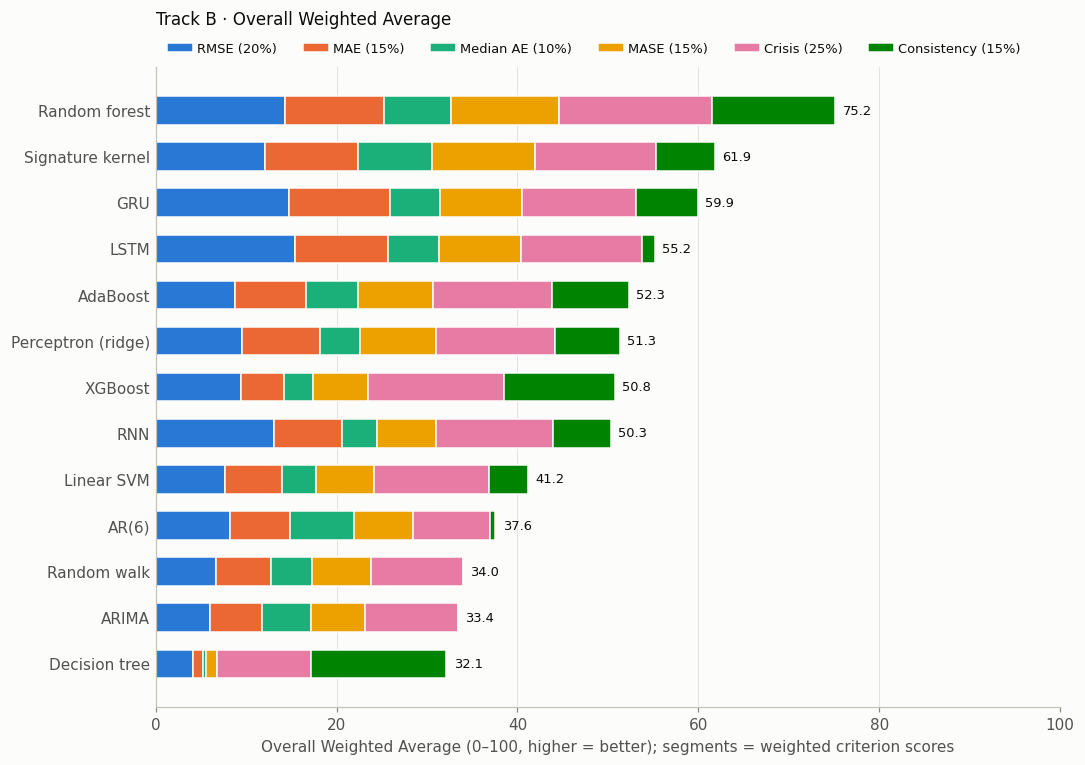

In [7]:
owa_bars(lb_main, f"Track {MAIN_TRACK} · Overall Weighted Average", f"owa_{MAIN_TRACK}")

### 2.3 Mean rank by metric, target and horizon

Rows in OWA order. Each column averages the model's rank over the other dimensions. Dark = better. Reading across a row shows where a model is strong and where it is weak.

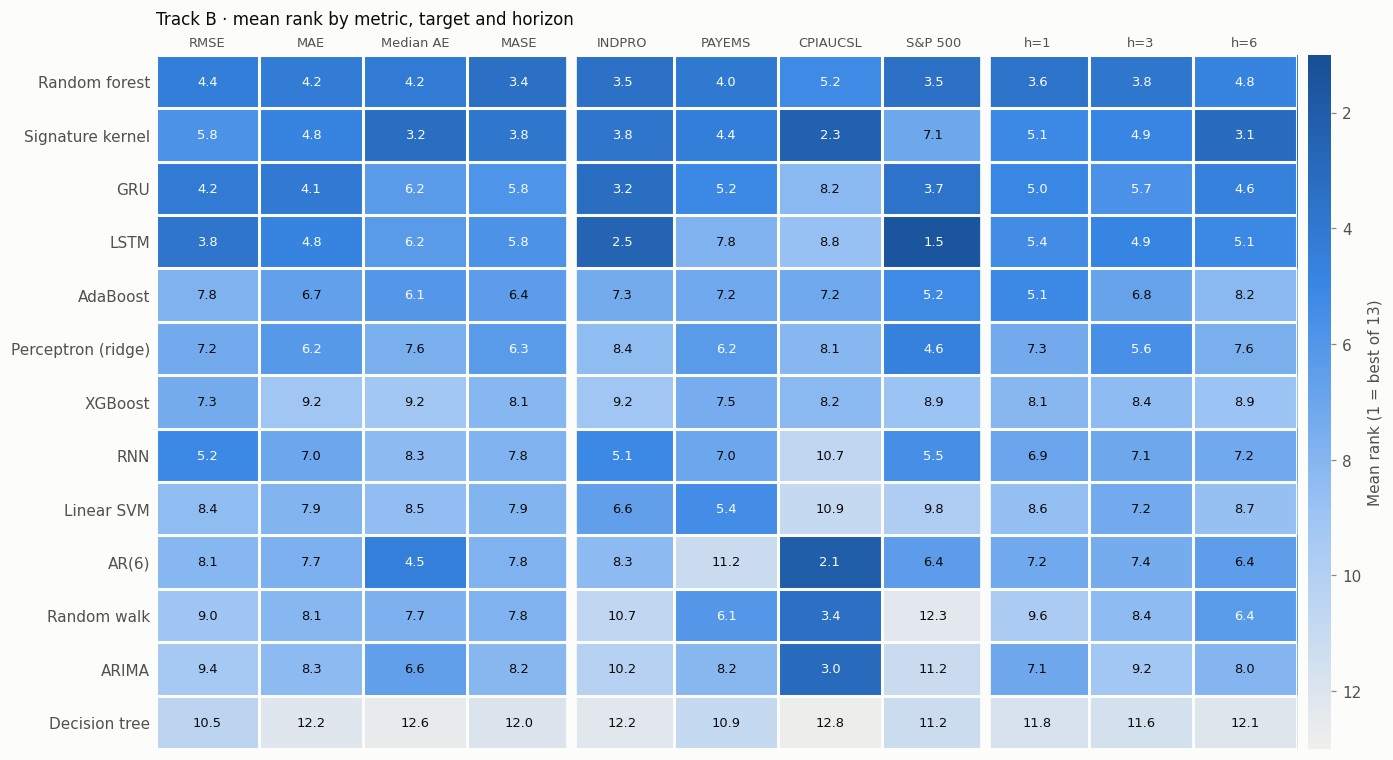

In [8]:
dim_table, groups = by_dimension(main_ranks, ORDER)
save_table(dim_table, f"by_dimension_{MAIN_TRACK}")
rank_heatmap(dim_table, f"Track {MAIN_TRACK} · mean rank by metric, target and horizon", N_MAIN,
             f"by_dimension_{MAIN_TRACK}", groups=groups)

### 2.4 Mean rank by target and horizon

Averaged over the four metrics.

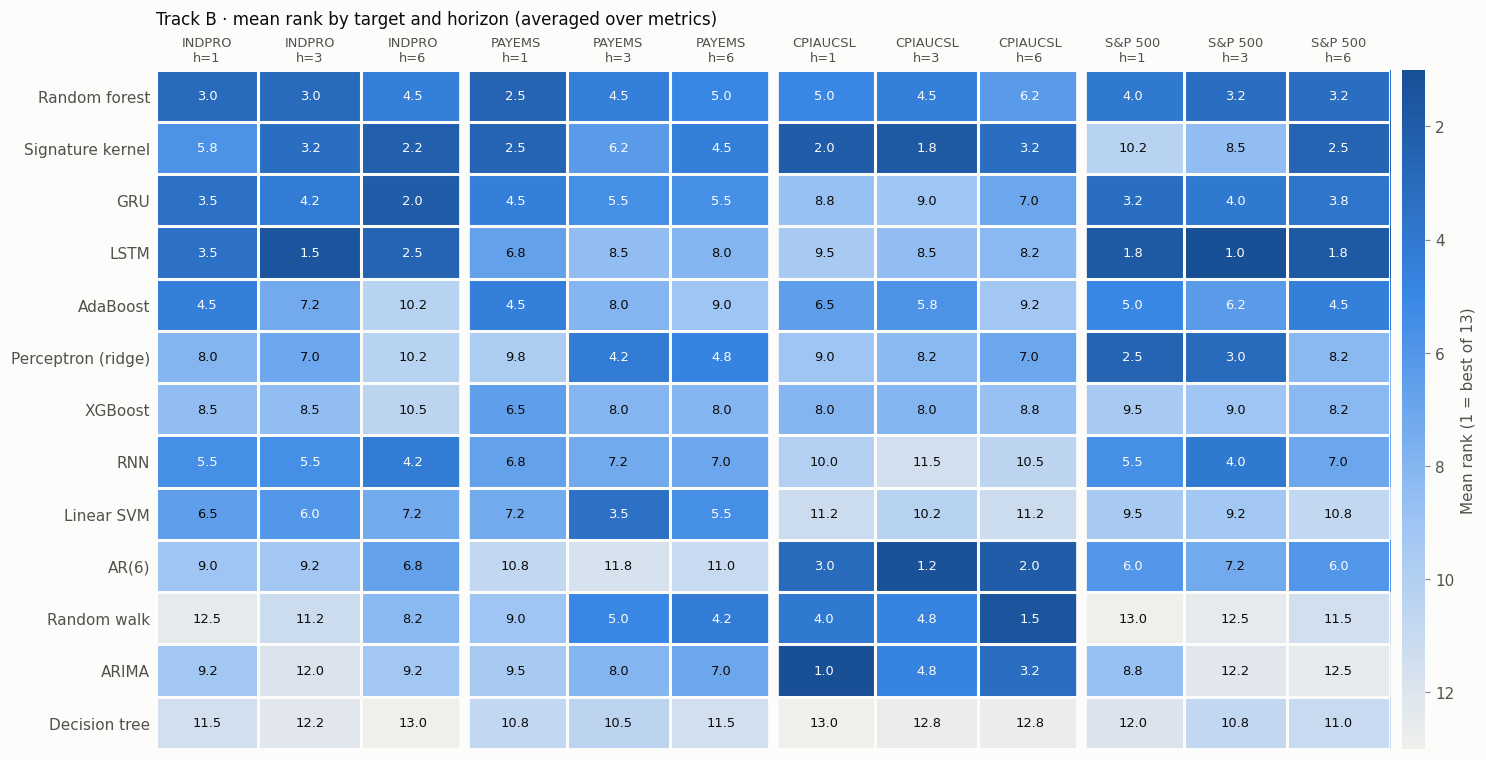

In [9]:
th_table = mean_rank(main_ranks, ["target", "horizon"], ORDER,
                     pd.MultiIndex.from_product([TARGETS, HORIZONS], names=["target", "horizon"]))
save_table(th_table, f"by_target_horizon_{MAIN_TRACK}")
rank_heatmap(th_table, f"Track {MAIN_TRACK} · mean rank by target and horizon (averaged over metrics)", N_MAIN,
             f"by_target_horizon_{MAIN_TRACK}", groups=[len(HORIZONS)] * len(TARGETS))

### 2.5 Rank spread

Every cell's rank as a dot, coloured by target, with the mean rank as a black bar. A tight cluster is a consistent model; dots spread across the axis, or split by colour, is a specialist.

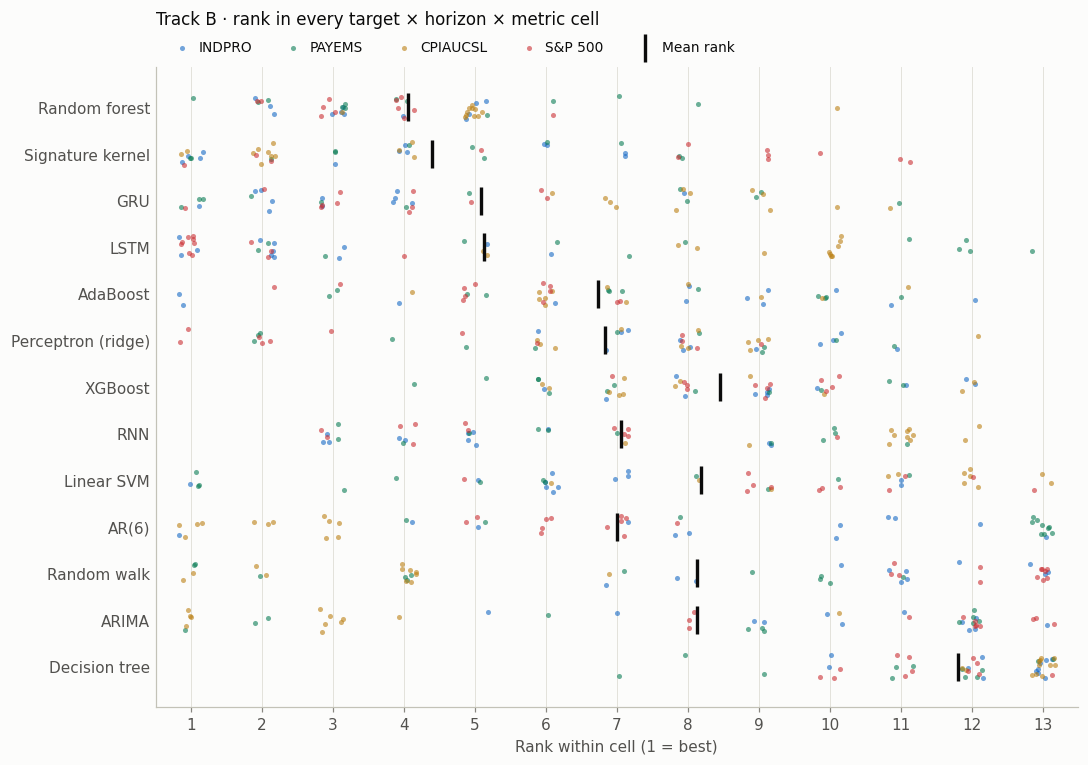

In [10]:
rank_spread(main_ranks, ORDER, f"Track {MAIN_TRACK} · rank in every target × horizon × metric cell", f"spread_{MAIN_TRACK}")

## 3. Recessions, expansions and COVID

The same ranking, recomputed separately over test months in three non-overlapping regimes:

- Expansion: NBER `USREC = 0`, outside the COVID window
- Recession: `USREC = 1`, outside the COVID window (1973–75, 1980, 1981–82, 1990–91, 2001, 2008–09)
- COVID: test months in `COVID_WINDOW`, kept apart because its errors are large enough to swamp the other recessions

Recession and COVID cells rest on far fewer months than expansion cells (counts below), so read them as indicative.

In [11]:
months = (main_runs.groupby(["regime", "horizon"])["test_start"].nunique()
          .unstack("horizon").reindex(REGIMES).rename(columns=lambda h: f"h={h}"))
months.index.name = "test months"
months

horizon,h=1,h=3,h=6
test months,,,
Expansion,558,556,553
Recession,72,72,72
COVID,16,16,16


### 3.1 Mean rank by regime

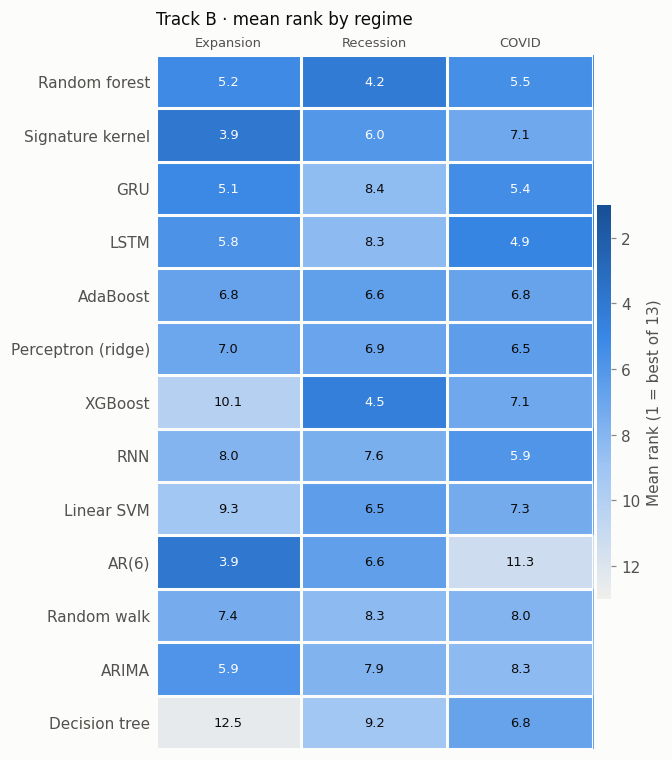

In [12]:
reg_table = mean_rank(reg_ranks, ["regime"], ORDER, REGIMES)
save_table(reg_table, f"by_regime_{MAIN_TRACK}")
rank_heatmap(reg_table, f"Track {MAIN_TRACK} · mean rank by regime", N_MAIN, f"by_regime_{MAIN_TRACK}")

### 3.2 Mean rank by regime and target

Averaged over horizons and metrics.

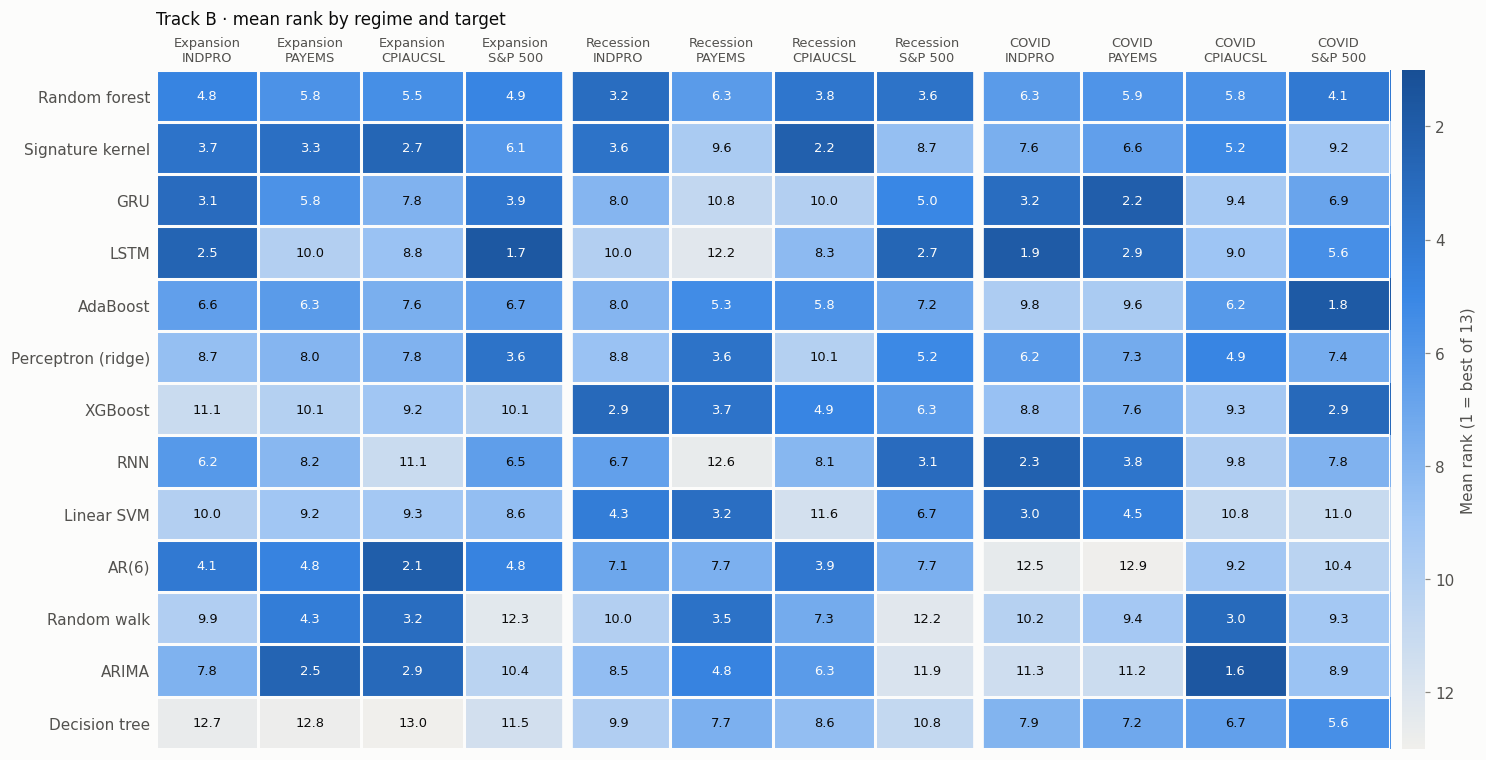

In [13]:
rt_table = mean_rank(reg_ranks, ["regime", "target"], ORDER,
                     pd.MultiIndex.from_product([REGIMES, TARGETS], names=["regime", "target"]))
save_table(rt_table, f"by_regime_target_{MAIN_TRACK}")
rank_heatmap(rt_table, f"Track {MAIN_TRACK} · mean rank by regime and target", N_MAIN,
             f"by_regime_target_{MAIN_TRACK}", groups=[len(TARGETS)] * len(REGIMES))

### 3.3 Rank shift in a crisis

Mean rank in each crisis regime minus mean rank in expansion. Negative = the model moves up the ranking when conditions turn; positive = it falls back.

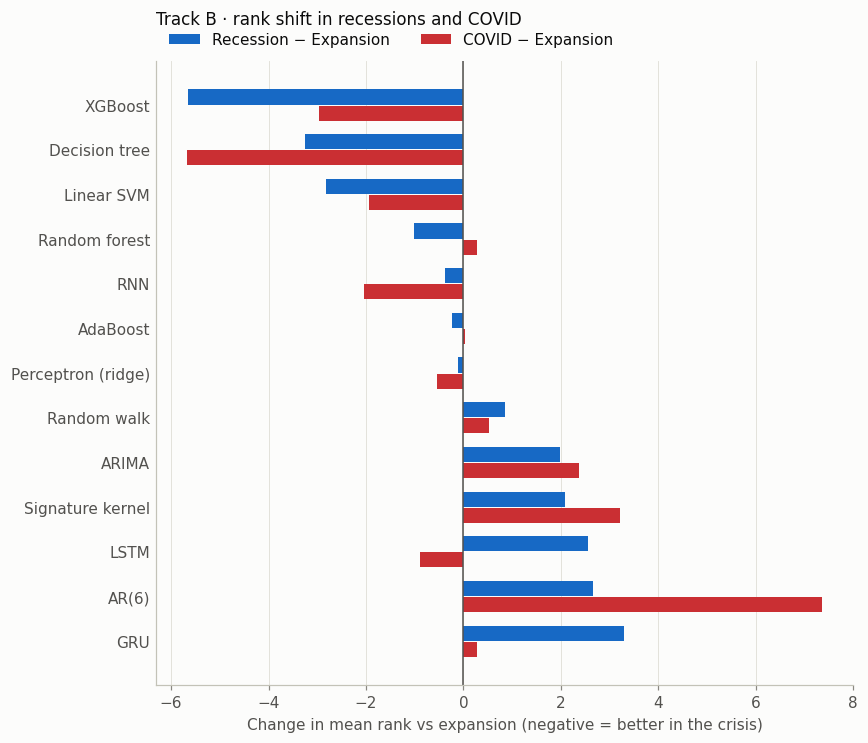

,Recession − Expansion,COVID − Expansion
entry,,
XGBoost,-5.65,-2.96
Decision tree,-3.25,-5.67
Linear SVM,-2.81,-1.94
Random forest,-1.02,0.27
RNN,-0.38,-2.04
AdaBoost,-0.23,0.04
Perceptron (ridge),-0.10,-0.54
Random walk,0.84,0.52
ARIMA,1.99,2.38


In [14]:
shift = reg_table[["Recession", "COVID"]].sub(reg_table["Expansion"], axis=0)
shift.columns = [f"{c} − Expansion" for c in shift.columns]
shift = shift.sort_values(shift.columns[0])
save_table(shift, f"regime_shift_{MAIN_TRACK}")

fig, ax = plt.subplots(figsize=(8, 0.42 * len(shift) + 1.4))
y = np.arange(len(shift))
for k, (col, color) in enumerate(zip(shift.columns, ["#1769c5", "#ca2f33"])):
    ax.barh(y + (k - 0.5) * 0.36, shift[col], height=0.34, color=color, label=col)
ax.axvline(0, color=INK_2, linewidth=1)
ax.set_yticks(y, [entry_label(e) for e in shift.index])
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.set_xlabel("Change in mean rank vs expansion (negative = better in the crisis)")
ax.set_title(f"Track {MAIN_TRACK} · rank shift in recessions and COVID", loc="left", pad=24)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
fig.tight_layout()
save(fig, f"regime_shift_{MAIN_TRACK}")
plt.show()
shift.rename(index=entry_label).round(2)

### Findings: regimes

Results as of the current run. Recession cells rest on 72 test months and COVID cells on 16, so treat these as indicative.

- Random forest and AdaBoost stay in the top group in every regime, though both slip a little in COVID (+1.7 and +1.5 places).
- XGBoost moves up the most in recessions (−4.7 places). It ranks 1.8 to 3.9 on every target in recession months, against 6.5 to 8.8 in expansions, which is why it scores close to random forest on the OWA crisis criterion.
- Decision tree and linear SVM are weak in normal times but move up in both crises (−4.2 / −4.5 and −2.6 / −2.6 places).
- The recurrent models are COVID specialists: LSTM is the best model for INDPRO in COVID months (1.9), GRU the best for PAYEMS (2.2) and the RNN ranks 2.3 on INDPRO. GRU and LSTM fall back in ordinary recessions (+2.9 and +2.3 places).
- AR(6) shows the opposite pattern. It ranks well in expansions, especially for CPI (2.1), but falls 6.3 places in COVID, where it is last for INDPRO and PAYEMS (12.8 and 12.9 of 13): a linear autoregression extrapolates the shock. ARIMA and the signature kernel also lose ground in crises.

## 4. Model profiles

Each model on `MAIN_TRACK` gets one or more labels from simple rules over the tables above, listed in OWA order. With `n` entries, the top third means a mean rank of at most 1 + (n − 1)/3, and the shift thresholds are shares of the rank range n − 1, so the same rules work for any number of entries:

- Consistently strong: mean rank in the top third and rank SD at or below the median SD
- Consistently weak: mean rank in the bottom third and rank SD at or below the median SD
- Target or horizon specialist: top third on average for at least one target (or horizon) and in the bottom half for another
- Metric-sensitive: mean RMSE rank differs from the mean MAE / median AE rank by at least `METRIC_SHIFT` × (n − 1). Worse on RMSE means occasional large misses
- Regime specialist: mean rank moves by at least `REGIME_SHIFT` × (n − 1) places between expansion and recession or COVID
- Middle of the pack: none of the above

In [15]:
prof_main = profile(main_ranks, reg_ranks)
save_table(prof_main, f"profiles_{MAIN_TRACK}")
summarize_profiles(prof_main)
prof_main.rename(index=entry_label)

Consistently strong
  Random forest                      OWA  75.2   mean rank  4.06   
  Signature kernel                   OWA  61.9   mean rank  4.40   strong on CPIAUCSL (2.3), weak on S&P 500 (7.1)

Target specialist
  Signature kernel                   OWA  61.9   mean rank  4.40   strong on CPIAUCSL (2.3), weak on S&P 500 (7.1)
  GRU                                OWA  59.9   mean rank  5.08   strong on INDPRO (3.2), weak on CPIAUCSL (8.2)
  LSTM                               OWA  55.2   mean rank  5.12   strong on S&P 500 (1.5), weak on CPIAUCSL (8.8)
  Perceptron (ridge)                 OWA  51.3   mean rank  6.83   strong on S&P 500 (4.6), weak on INDPRO (8.4)
  AR(6)                              OWA  37.6   mean rank  7.00   strong on CPIAUCSL (2.1), weak on PAYEMS (11.2); worse in COVID (+7.4 places vs expansion)
  Random walk                        OWA  34.0   mean rank  8.12   strong on CPIAUCSL (3.4), weak on S&P 500 (12.3)
  ARIMA                              OWA  33.4 

,owa,mean_rank,rank_sd,profile,notes
entry,,,,,
Random forest,75.2,4.06,1.68,Consistently strong,
Signature kernel,61.9,4.40,3.03,"Consistently strong, Target specialist","strong on CPIAUCSL (2.3), weak on S&P 500 (7.1)"
GRU,59.9,5.08,2.97,Target specialist,"strong on INDPRO (3.2), weak on CPIAUCSL (8.2)"
LSTM,55.2,5.12,3.99,Target specialist,"strong on S&P 500 (1.5), weak on CPIAUCSL (8.8)"
AdaBoost,52.3,6.73,2.66,Middle of the pack,
Perceptron (ridge),51.3,6.83,2.90,Target specialist,"strong on S&P 500 (4.6), weak on INDPRO (8.4)"
XGBoost,50.8,8.46,1.93,Regime specialist,better in Recession (-5.6 places vs expansion)
RNN,50.3,7.06,3.07,Metric-sensitive,RMSE rank -2.5 vs MAE/median AE: avoids large ...
Linear SVM,41.2,8.19,3.43,Middle of the pack,


### Findings: OWA and model profiles on Track B

- Random forest leads the OWA (83.0) and has the top score on every criterion: it is the most consistent model (rank SD 1.6), never worse than 5th, and the best in crises (70.7). Its only soft spot is CPI (mean rank 4.8).
- AdaBoost is second (71.8). It matches random forest on MAE and MASE but scores 62.5 on RMSE, about two places worse than on MAE: occasional large misses.
- The OWA reorders the middle of the table. XGBoost is third (60.9) although its mean rank (5.9) is behind the signature kernel's (5.6), because it holds up best in recessions. AR(6) has the 5th best mean rank (7.6) but drops to 11th on OWA because it is the second least consistent model and weak in crises (31.5). ARIMA is last on OWA as the least consistent model (rank SD 4.4).
- Recurrent models land in the upper middle: GRU 4th (55.9), LSTM 6th (51.6), RNN 7th (46.6). LSTM is the best non-tree model on RMSE (68.1) but inconsistent: strong on S&P 500 (3.4), weak on CPI (9.0) and PAYEMS (8.6).
- CPI has a different winner set from the other targets: AR(6) (2.1), the signature kernel (2.3), ARIMA (3.1) and the random walk (3.5) beat every tree ensemble. Inflation is persistent, so simple time-series structure beats the curated predictors.
- Consistently weak: linear SVM (38.7) and the single decision tree (35.9).

## 5. Configurations: model@track across all tracks

Each model × track pair is ranked as its own entry, so the effect of the input track (A vs B, quantum reservoir tracks vs B) sits on the same leaderboard as the model choice, and every configuration gets an OWA on the same scale. Models in `FEATURELESS` score the same on every track and appear once. Only pairs that have results are ranked; fold matching is across all entries in each cell.

The tables keep every configuration; the per-entry plots show the top `CFG_SHOW` by OWA.

In [16]:
cfg_runs = ok[~ok["model"].isin(FEATURELESS) | (ok["track"] == MAIN_TRACK)].copy()
cfg_runs["entry"] = np.where(cfg_runs["model"].isin(FEATURELESS), cfg_runs["model"],
                             cfg_runs["model"] + "@" + cfg_runs["track"])

# check the featureless models really are identical across tracks
for m in FEATURELESS:
    d = ok[ok["model"] == m].pivot_table(index=["target", "horizon", "fold_id"], columns="track", values="mse")
    if d.shape[1] > 1:
        print(f"{m}: max spread in fold MSE across {d.shape[1]} tracks = {(d.max(axis=1) - d.min(axis=1)).max():.2e}")

cfg_metrics = cell_metrics(cfg_runs, CELL)
cfg_ranks = rank_cells(cfg_metrics, CELL)
check_ranks(cfg_ranks, CELL)
cfg_ranks["model"] = cfg_ranks["entry"].str.partition("@")[0]
cfg_ranks["track"] = cfg_ranks["entry"].str.partition("@")[2].replace("", MAIN_TRACK)
N_CFG = int(cfg_ranks["n"].max())

cfg_reg_metrics = cell_metrics(cfg_runs, REG_CELL)
cfg_reg_ranks = rank_cells(cfg_reg_metrics, REG_CELL)

lb_cfg = leaderboard(cfg_ranks, cfg_reg_ranks)
CFG_ORDER = list(lb_cfg.index)
CFG_TOP = CFG_ORDER[:CFG_SHOW]
save_table(lb_cfg, "leaderboard_configurations")
print(f"{N_CFG} configurations; top {CFG_SHOW} by OWA:")
lb_cfg.head(CFG_SHOW).rename(index=entry_label).round(2)

random_walk: max spread in fold MSE across 13 tracks = 0.00e+00
AR6: max spread in fold MSE across 13 tracks = 3.59e-03


133 configurations; top 25 by OWA:


,owa_rank,rmse,mae,median_ae,mase,crisis,consistency,owa,mean_rank,median_rank,rank_sd,best,worst,top3_share,cells
entry,,,,,,,,,,,,,,,
LSTM · MCR_su_z,1,92.05,86.81,81.31,84.60,68.21,70.56,79.89,19.23,14.5,17.68,1.0,72.0,0.21,48
LSTM · B,2,86.43,83.96,79.29,80.68,69.91,64.88,77.12,23.98,18.0,20.63,2.0,78.0,0.17,48
GRU · MCR_su_z,3,86.24,81.12,72.79,77.53,60.42,76.74,74.94,28.17,23.5,14.47,4.0,69.0,0.00,48
Random forest · B,4,72.66,81.31,81.12,83.96,68.06,64.35,74.10,27.71,22.5,20.91,1.0,91.0,0.04,48
GRU · B,5,82.45,82.26,75.57,78.03,65.75,63.78,74.10,27.96,23.5,21.20,1.0,80.0,0.10,48
Perceptron (ridge) · Q_su_pce,6,81.82,81.38,74.18,77.78,56.63,77.07,73.37,29.00,29.5,14.29,6.0,58.0,0.00,48
Perceptron (ridge) · MCR_su_z,7,83.96,78.91,67.11,75.88,63.49,68.03,72.80,32.06,30.5,18.99,6.0,86.0,0.00,48
Random forest · A,8,77.59,86.36,85.10,88.07,56.31,55.71,72.63,21.75,13.0,25.39,1.0,102.0,0.27,48
Signature kernel · Q_zz_pauli,9,64.77,87.82,90.21,89.46,61.84,55.41,72.34,23.35,10.0,25.55,1.0,92.0,0.12,48


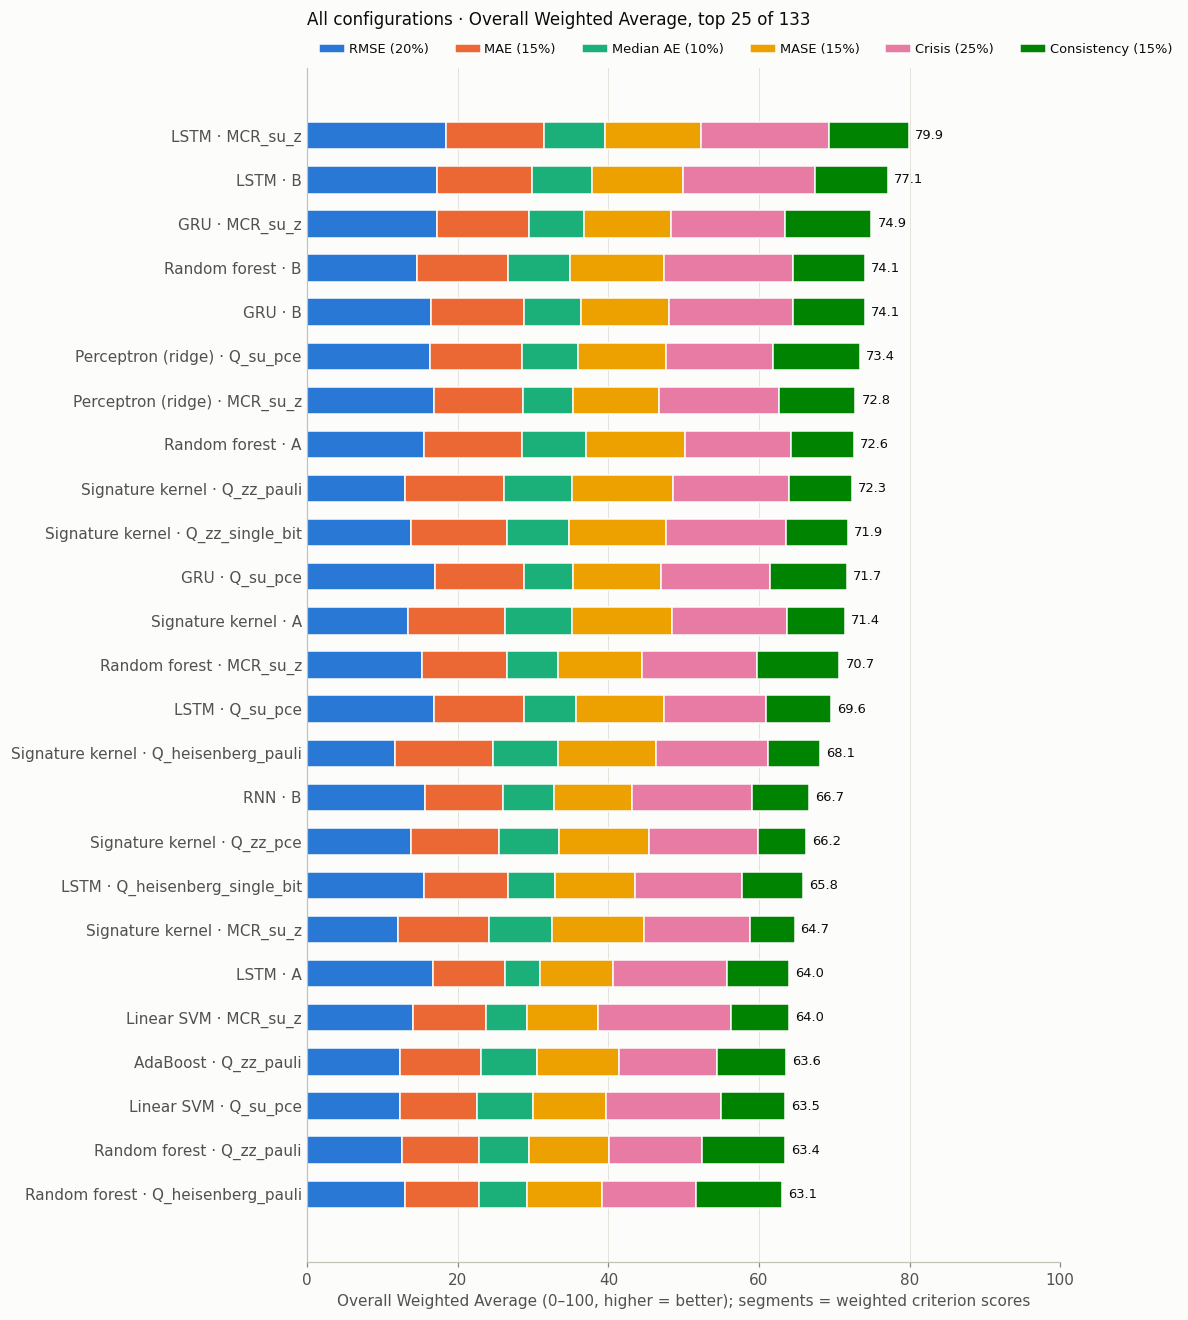

In [17]:
owa_bars(lb_cfg.head(CFG_SHOW), f"All configurations · Overall Weighted Average, top {CFG_SHOW} of {N_CFG}",
         "owa_configurations")

### 5.1 OWA by model and track

The configuration OWA laid out with models as rows and tracks as columns. Reading across a row shows how much the input track matters for that model.

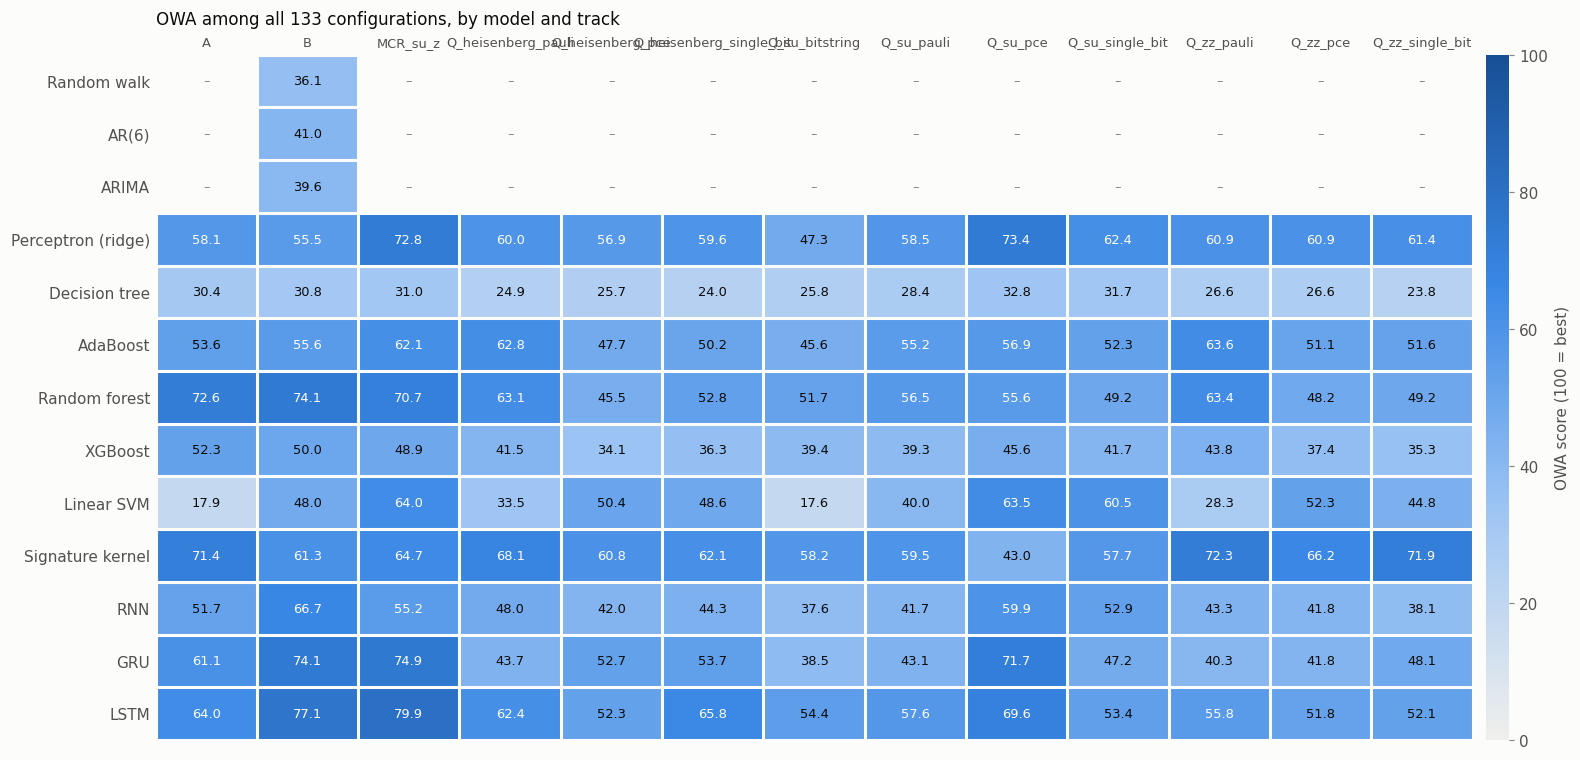

In [18]:
parts = lb_cfg.index.to_series().str.partition("@")
cfg_owa = pd.DataFrame({"owa": lb_cfg["owa"], "model": parts[0], "track": parts[2].replace("", MAIN_TRACK)})
owa_mt = (cfg_owa.pivot(index="model", columns="track", values="owa")
          .reindex(index=[m for m in MODELS if m in set(cfg_owa["model"])], columns=TRACKS))
save_table(owa_mt, "owa_by_model_track")
rank_heatmap(owa_mt, f"OWA among all {N_CFG} configurations, by model and track", N_CFG, "owa_by_model_track", score=True)

### 5.2 Configurations by metric, target, horizon and regime

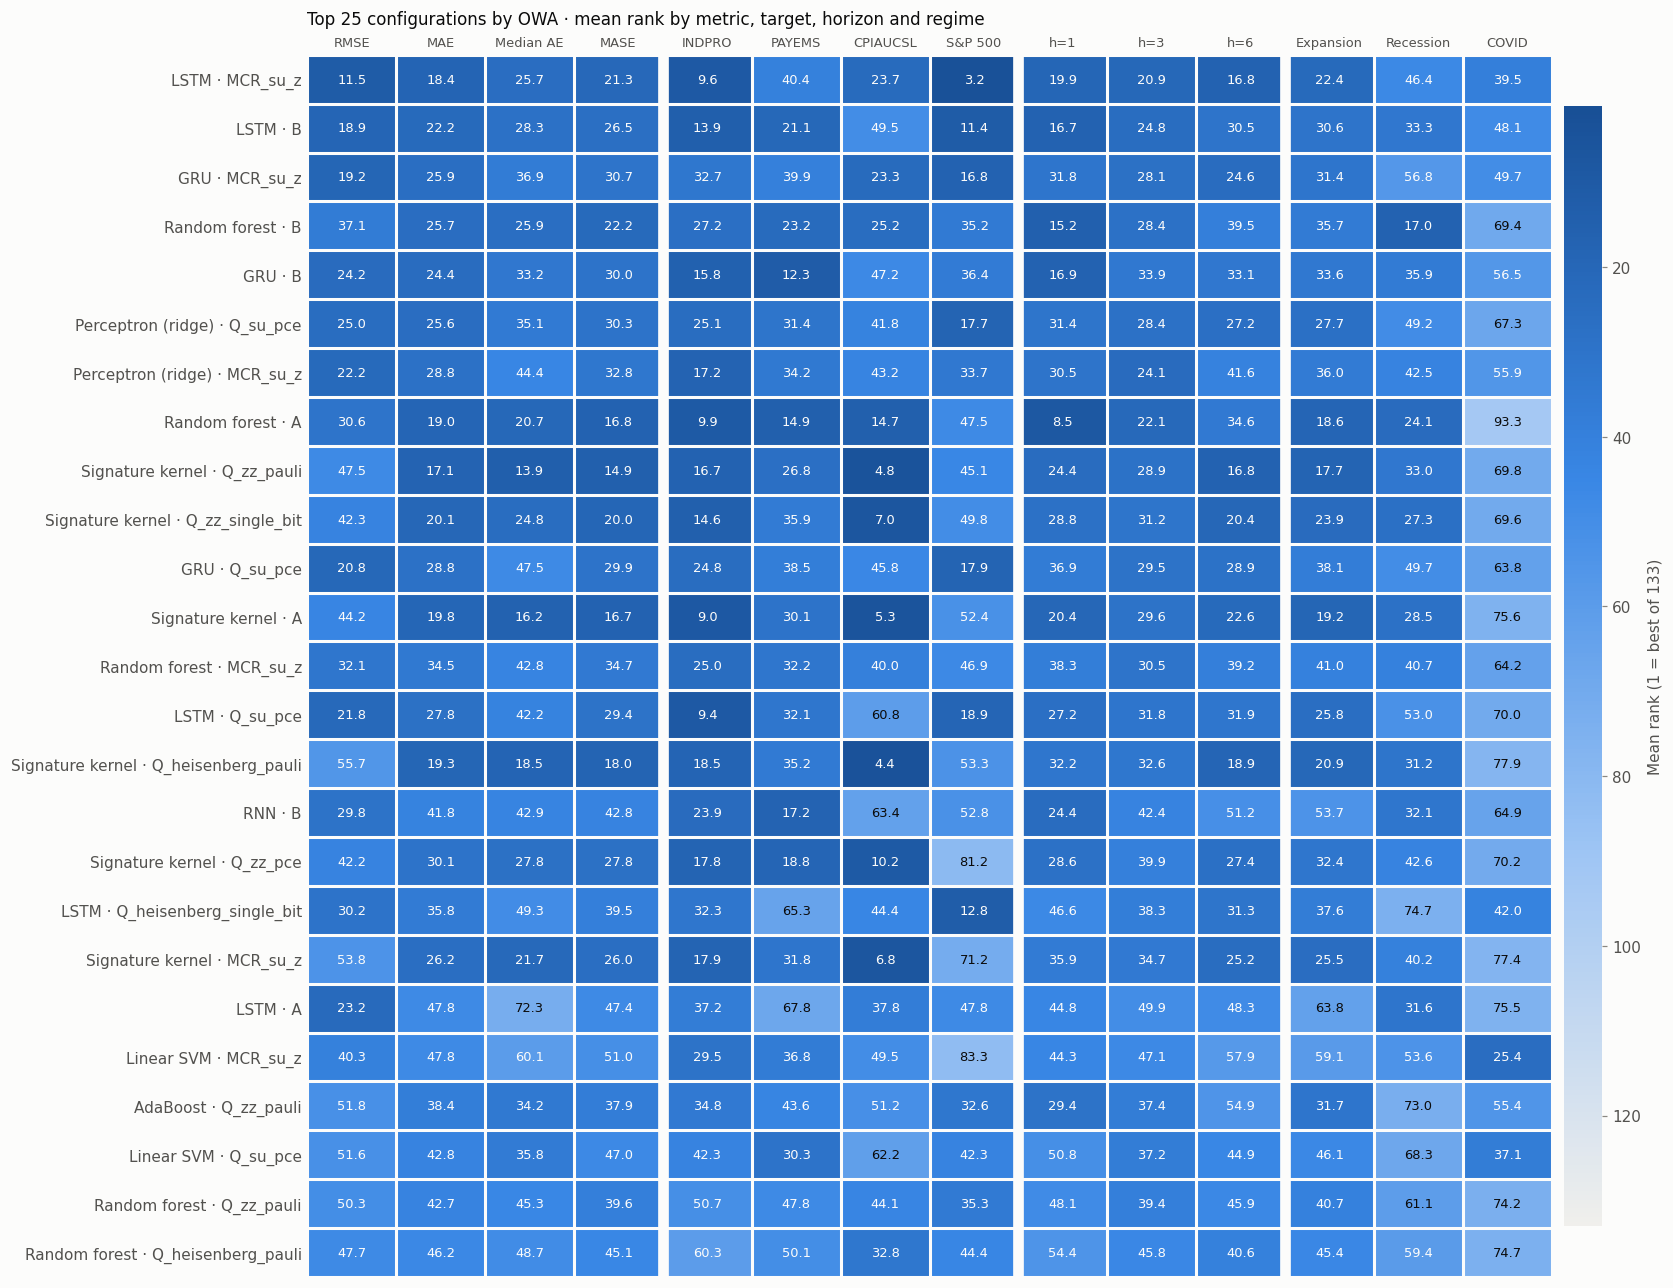

In [19]:
cfg_dim, cfg_groups = by_dimension(cfg_ranks, CFG_ORDER)
cfg_reg = mean_rank(cfg_reg_ranks, ["regime"], CFG_ORDER, REGIMES)
cfg_all = pd.concat([cfg_dim, cfg_reg], axis=1)
save_table(cfg_all, "by_dimension_configurations")
rank_heatmap(cfg_all.loc[CFG_TOP], f"Top {CFG_SHOW} configurations by OWA · mean rank by metric, target, horizon and regime",
             N_CFG, "by_dimension_configurations", groups=[*cfg_groups, len(REGIMES)])

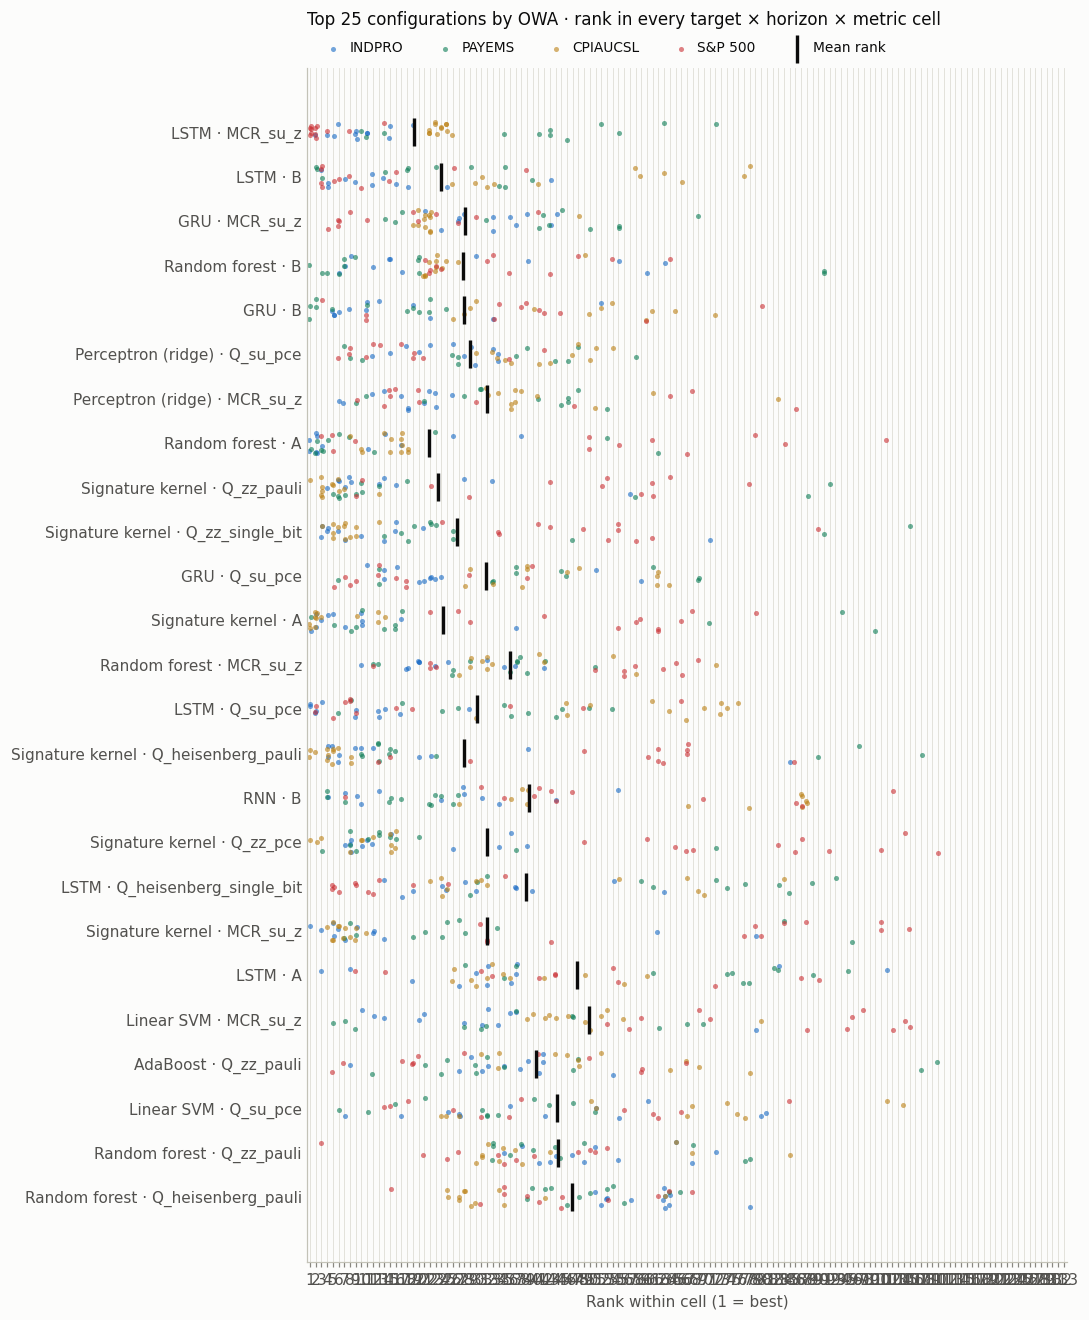

In [20]:
rank_spread(cfg_ranks[cfg_ranks["entry"].isin(CFG_TOP)], CFG_TOP,
            f"Top {CFG_SHOW} configurations by OWA · rank in every target × horizon × metric cell", "spread_configurations")

### 5.3 Configuration profiles

The rules from section 4, applied to the configuration ranking. Thresholds use every configuration; the printout lists the top `CFG_SHOW`.

In [21]:
prof_cfg = profile(cfg_ranks, cfg_reg_ranks)
save_table(prof_cfg, "profiles_configurations")
summarize_profiles(prof_cfg, top=CFG_SHOW)
prof_cfg.head(CFG_SHOW).rename(index=entry_label)

Consistently strong
  LSTM · MCR_su_z                    OWA  79.9   mean rank 19.23   
  LSTM · B                           OWA  77.1   mean rank 23.98   
  GRU · MCR_su_z                     OWA  74.9   mean rank 28.17   
  Random forest · B                  OWA  74.1   mean rank 27.71   
  GRU · B                            OWA  74.1   mean rank 27.96   
  Perceptron (ridge) · Q_su_pce      OWA  73.4   mean rank 29.00   
  Perceptron (ridge) · MCR_su_z      OWA  72.8   mean rank 32.06   
  Random forest · A                  OWA  72.6   mean rank 21.75   worse in COVID (+74.7 places vs expansion)
  GRU · Q_su_pce                     OWA  71.7   mean rank 31.75   
  Random forest · MCR_su_z           OWA  70.7   mean rank 36.02   
  LSTM · Q_su_pce                    OWA  69.6   mean rank 30.31   worse in COVID (+44.3 places vs expansion)
  AdaBoost · Q_zz_pauli              OWA  63.6   mean rank 40.56   worse in Recession (+41.3 places vs expansion)
  Linear SVM · Q_su_pce           

,owa,mean_rank,rank_sd,profile,notes
entry,,,,,
LSTM · MCR_su_z,79.9,19.23,17.68,Consistently strong,
LSTM · B,77.1,23.98,20.63,Consistently strong,
GRU · MCR_su_z,74.9,28.17,14.47,Consistently strong,
Random forest · B,74.1,27.71,20.91,Consistently strong,
GRU · B,74.1,27.96,21.20,Consistently strong,
Perceptron (ridge) · Q_su_pce,73.4,29.00,14.29,Consistently strong,
Perceptron (ridge) · MCR_su_z,72.8,32.06,18.99,Consistently strong,
Random forest · A,72.6,21.75,25.39,"Consistently strong, Regime specialist",worse in COVID (+74.7 places vs expansion)
Signature kernel · Q_zz_pauli,72.3,23.35,25.55,"Metric-sensitive, Regime specialist",RMSE rank +32.0 vs MAE/median AE: occasional l...


### Findings: configurations across tracks

- Track A (full 123-variable panel) beats Track B (curated) for every tree model on OWA: random forest 91.1 vs 87.2, AdaBoost 80.3 vs 78.6, XGBoost 78.1 vs 71.5, decision tree 46.6 vs 39.5. The top five of 117 configurations are all tree ensembles on A or B.
- The A-track ensembles are also the configurations that lose the most ground in COVID (52 to 58 places among 117). AdaBoost@A is metric-sensitive: it wins the typical month but has some large misses, which costs it on the RMSE criterion.
- The best quantum configuration is AdaBoost@Q_su_pauli, 6th of 117 (OWA 73.6), followed by AdaBoost@Q_zz_pauli (72.8) and random forest@Q_zz_pauli (72.4). Each is still below the same model on Track B.
- Pauli readouts give the strongest tree-based quantum configurations; the PCE readout on the SU(2) reservoir gives the strongest linear and recurrent ones (ridge perceptron 68.3, GRU 67.7, LSTM 66.4 on Q_su_pce).

## 6. Quantum tracks vs classical

Each quantum track is a reservoir embedding of the Track B predictors, so the classical reference for model m on quantum track Q is the same model on `CLASSICAL_BASELINE`:

ΔOWA(m, Q) = OWA(m@Q) − OWA(m@B)

Both OWAs come from the configuration ranking in section 5, so they are on the same scale. Positive = the quantum features improved on the classical input. Featureless models are left out. A track's overall improvement is its mean ΔOWA across the models run on it; the track with the highest mean is highlighted.

In [22]:
q_tracks = [t for t in QUANTUM_TRACKS if t in owa_mt.columns]
delta = (owa_mt[q_tracks].sub(owa_mt[CLASSICAL_BASELINE], axis=0)
         .drop(index=FEATURELESS, errors="ignore").dropna(how="all"))
q_summary = pd.DataFrame({
    "mean_delta":      delta.mean(),
    "median_delta":    delta.median(),
    "models_improved": (delta > 0).sum(),
    "models":          delta.notna().sum(),
    "best_model":      delta.idxmax().map(entry_label),
    "best_delta":      delta.max(),
    "best_owa":        owa_mt[q_tracks].max(),
}).sort_values("mean_delta", ascending=False)
q_summary.index.name = "quantum track"
BEST_Q = q_summary.index[0]
save_table(q_summary, "quantum_vs_classical")
delta = delta[q_summary.index]
save_table(delta, "quantum_delta_owa")

best = q_summary.loc[BEST_Q]
print(f"Quantum track with the greatest improvement over classical (Track {CLASSICAL_BASELINE}): {BEST_Q}")
print(f"  mean ΔOWA {best['mean_delta']:+.1f} points; improves {best['models_improved']} of {best['models']} models; "
      f"largest gain {best['best_model']} ({best['best_delta']:+.1f})")
if best["mean_delta"] <= 0:
    print(f"  no quantum track beats Track {CLASSICAL_BASELINE} on average; {BEST_Q} loses the least")
best_q_cfg = next(e for e in CFG_ORDER if e.partition("@")[2] in QUANTUM_TRACKS)
print(f"Best quantum configuration overall: {entry_label(best_q_cfg)}, OWA {lb_cfg.loc[best_q_cfg, 'owa']:.1f}, "
      f"#{lb_cfg.loc[best_q_cfg, 'owa_rank']} of {N_CFG} (leader: {entry_label(CFG_ORDER[0])}, OWA {lb_cfg['owa'].iloc[0]:.1f})")

(q_summary.style
 .format({"mean_delta": "{:+.1f}", "median_delta": "{:+.1f}", "best_delta": "{:+.1f}", "best_owa": "{:.1f}"})
 .apply(lambda r: [f"background-color: #cde2fb; font-weight: 600" if r.name == BEST_Q else ""] * len(r), axis=1))

Quantum track with the greatest improvement over classical (Track B): MCR_su_z
  mean ΔOWA +3.1 points; improves 7 of 10 models; largest gain Perceptron (ridge) (+17.3)
Best quantum configuration overall: LSTM · MCR_su_z, OWA 79.9, #1 of 133 (leader: LSTM · MCR_su_z, OWA 79.9)


,mean_delta,median_delta,models_improved,models,best_model,best_delta,best_owa
quantum track,,,,,,,
MCR_su_z,+3.1,+1.8,7,10,Perceptron (ridge),+17.3,79.9
Q_su_pce,-2.1,-3.4,4,10,Perceptron (ridge),+17.9,73.4
Q_su_single_bit,-8.4,-5.9,3,10,Linear SVM,+12.6,62.4
Q_heisenberg_pauli,-8.5,-9.7,3,10,AdaBoost,+7.1,68.1
Q_zz_pauli,-9.5,-8.5,3,10,Signature kernel,+11.1,72.3
Q_heisenberg_single_bit,-9.6,-9.1,3,10,Perceptron (ridge),+4.1,65.8
Q_su_pauli,-11.3,-9.3,1,10,Perceptron (ridge),+3.0,59.5
Q_zz_pce,-11.5,-8.6,3,10,Perceptron (ridge),+5.4,66.2
Q_zz_single_bit,-11.7,-10.9,2,10,Signature kernel,+10.6,71.9


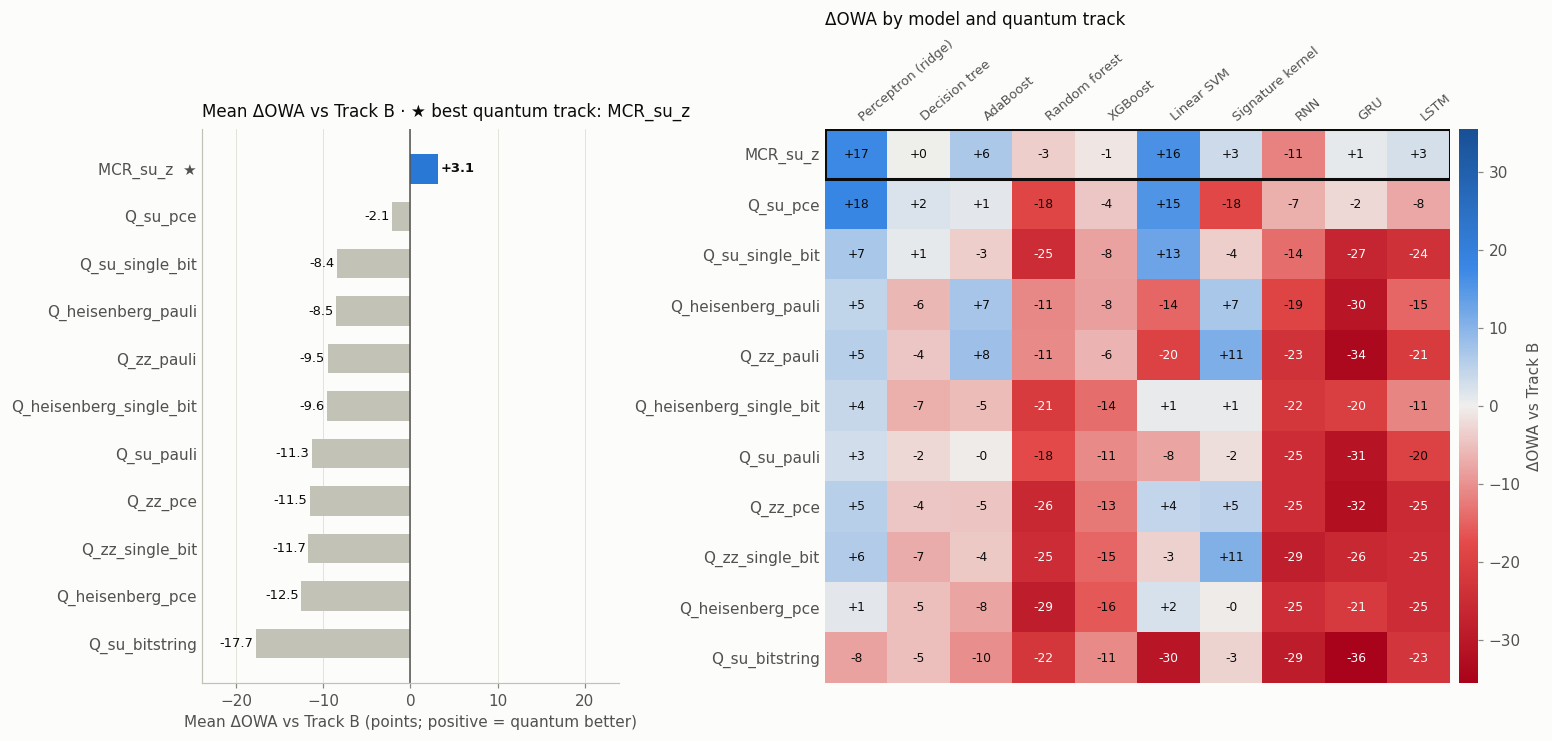

In [23]:
fig, (ax, hx) = plt.subplots(1, 2, figsize=(14, 0.42 * max(len(q_tracks), len(delta)) + 2),
                             gridspec_kw={"width_ratios": [1, 1.5]}, layout="constrained")

# left: mean ΔOWA per quantum track, winner highlighted
y = np.arange(len(q_summary))
colors = [HIGHLIGHT if t == BEST_Q else AXIS for t in q_summary.index]
ax.barh(y, q_summary["mean_delta"], height=0.62, color=colors)
for i, (t, v) in enumerate(q_summary["mean_delta"].items()):
    ax.text(v + (0.3 if v >= 0 else -0.3), i, f"{v:+.1f}", va="center", ha="left" if v >= 0 else "right",
            fontsize=8.5, color=INK, fontweight="bold" if t == BEST_Q else "normal")
ax.axvline(0, color=INK_2, linewidth=1)
ax.set_yticks(y, [f"{t}  ★" if t == BEST_Q else t for t in q_summary.index])
ax.invert_yaxis()
lim = q_summary["mean_delta"].abs().max() * 1.35
ax.set_xlim(-lim, lim)
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.set_xlabel(f"Mean ΔOWA vs Track {CLASSICAL_BASELINE} (points; positive = quantum better)")
ax.set_title(f"Mean ΔOWA vs Track {CLASSICAL_BASELINE} · ★ best quantum track: {BEST_Q}", loc="left", pad=8)

# right: ΔOWA per model and quantum track (rows), winning track outlined
vals = delta.T.values.astype(float)
vmax = np.nanmax(np.abs(vals))
im = hx.imshow(vals, cmap=DELTA_CMAP, vmin=-vmax, vmax=vmax, aspect="auto")
for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        v = vals[i, j]
        hx.text(j, i, "–" if np.isnan(v) else f"{v:+.0f}", ha="center", va="center", fontsize=8,
                color=SURFACE if abs(v) > 0.55 * vmax else INK)
hx.set_xticks(range(len(delta)), [MODEL_LABELS.get(m, m) for m in delta.index], rotation=40, ha="left", fontsize=8.5)
hx.xaxis.tick_top()
hx.set_yticks(range(len(q_summary)), q_summary.index)
hx.add_patch(plt.Rectangle((-0.5, -0.5), vals.shape[1], 1, fill=False, edgecolor=INK, linewidth=2))
hx.grid(False)
hx.tick_params(which="both", length=0)
for side in hx.spines.values():
    side.set_visible(False)
cbar = fig.colorbar(im, ax=hx, fraction=0.03, pad=0.01, aspect=30)
cbar.set_label(f"ΔOWA vs Track {CLASSICAL_BASELINE}", color=INK_2)
cbar.outline.set_visible(False)
hx.set_title("ΔOWA by model and quantum track", loc="left", pad=8)

save(fig, "quantum_vs_classical")
plt.show()

### Findings: quantum vs classical

- Q_su_pce is the quantum track with the greatest improvement over classical: it has the highest mean ΔOWA of the ten quantum tracks (−5.5 points vs Track B). The mean is still negative, so no quantum track beats its classical input on average. The next best, Q_su_single_bit, averages −11.5, and Q_su_bitstring is worst (−20.0, no model improves).
- The gains go to models that cannot build nonlinear features themselves. Q_su_pce lifts the ridge perceptron by +17.1 (51.2 → 68.3) and linear SVM by +14.3 (45.3 → 59.6), and the perceptron improves on 9 of the 10 quantum tracks. The signature kernel gains +7 to +11 on the ZZ and Heisenberg Pauli tracks and Q_zz_single_bit.
- Strong nonlinear models lose: random forest, XGBoost and the recurrent nets drop 15 to 35 points on most quantum tracks, as the reservoir compresses information they could use directly. Q_su_pce is the exception for the recurrent models, keeping GRU almost level (−0.8) and RNN and LSTM within 6 points.
- For the BMO question, the evidence points to Q_su_pce with a linear readout (the standard QRC design) as the quantum configuration worth carrying forward. It is a real improvement on the classical linear model but does not reach the classical tree ensembles (68.3 vs 87.2 for random forest on Track B).